<a href="https://colab.research.google.com/github/hyperhacker1/Computational-Intelligence-Lab/blob/main/lab_2_completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tensorflow basis

## Example 1

Eager calculations in tensorflow

Add two variables a = 1 and b = 10


In [1]:
# Example
import numpy as np
import tensorflow as tf

print(tf.executing_eagerly())

a = tf.Variable(1)
b = tf.Variable(10)
c = a + b
print(c.numpy())

True
11


## Example 2


In [2]:
# Example
import numpy as np
import tensorflow as tf

@tf.function
def add(a,b):
  return a + b

def sub(a,b):
  return a - b

a = tf.Variable(5)
b = tf.Variable(6)
c = tf.Variable(1)

x = add(a,sub(b,c))
print(x.numpy())


10


# Task 1

Calculate by Tensorflow folowing expression $y = a * b + c$.

a,b, and c are 2x2 matrixes. Numbers in matrixes depends on your choice.
Multiplication is elementwise.


In [10]:
import tensorflow as tf
import numpy as np

a = tf.constant([[1, 2], [3, 4]], dtype=tf.float32)
b = tf.constant([[5, 6], [7, 8]], dtype=tf.float32)
c = tf.constant([[2, 2], [2, 2]], dtype=tf.float32)

y = a * b + c
print(y.numpy())


[[ 7. 14.]
 [23. 34.]]


# Example 3

Draw a graf of the function $y=f(x)=x^2$ and its derivatice $y'=f'(x). Use Tensoflow for derivative calculation.

[9. 4. 1. 0. 1. 4. 9.]
[-6. -4. -2.  0.  2.  4.  6.]


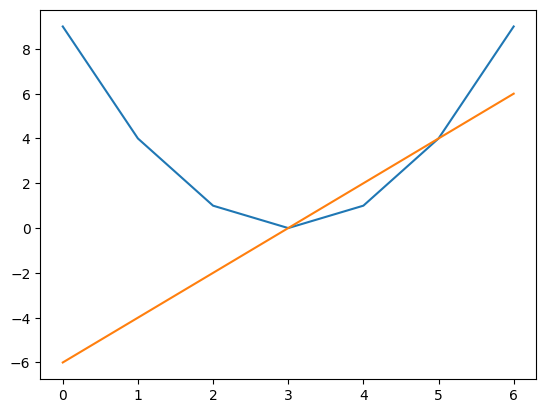

In [11]:
# Example
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

@tf.function
def f(x):
  y = x*x
  return y

@tf.function
def dfdx(x):
  y = f(x)
  return tf.gradients(y, x)[0]

x = tf.Variable([-3.,-2.,-1.,0.,1.,2.,3.])
print(f(x).numpy())
print(dfdx(x).numpy())

plt.plot(f(x))
plt.plot(dfdx(x))

# Task 2

Draw a graf of the function $y=\sigma(x)=\frac{1}{1+e^{-x}}$ and its derivative $y'=s'(x)$. Use Tensoflow for derivative calculation.

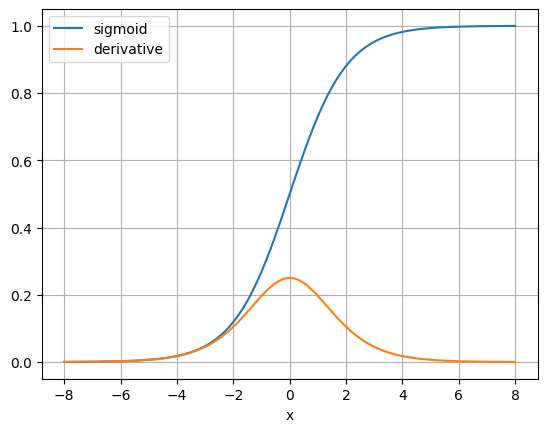

In [12]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

x = tf.Variable(np.linspace(-8, 8, 200), dtype=tf.float32)

with tf.GradientTape() as tape:
    y = 1 / (1 + tf.exp(-x))

dy = tape.gradient(y, x)

plt.plot(x.numpy(), y.numpy(), label='sigmoid')
plt.plot(x.numpy(), dy.numpy(), label='derivative')
plt.xlabel('x')
plt.legend()
plt.grid()
plt.show()


# Task 3

Calculate the gradient of function $y=g(x,y)=e^{-\frac{x^2+y^2}{2\sigma^2}}$ for $\sigma^2 = 0.5\;\mbox{and}\;x = 1\;\mbox{and}\;y = 1$

In [13]:
import tensorflow as tf
import numpy as np

x = tf.Variable(1.0)
y = tf.Variable(1.0)
sigma2 = 0.5

with tf.GradientTape() as tape:
    g = tf.exp(-(x*x + y*y) / (2 * sigma2))

gradient = tape.gradient(g, [x, y])
print('Function value:', g.numpy())
print('Gradient for x:', gradient[0].numpy())
print('Gradient for y:', gradient[1].numpy())


Function value: 0.13533528
Gradient for x: -0.27067056
Gradient for y: -0.27067056


# Task 4

Create a simple neural feed forward neural network using Tensorflow.

Input layer -> hidden layer -> output layer

for IRIS dataset

In [15]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix

# Load the Iris dataset
iris = np.loadtxt('iris.data', delimiter=',', usecols=(0, 1, 2, 3))

labels_text = []
with open('iris.data', 'r') as file:
    for line in file:
        if line.strip():
            labels_text.append(line.strip().split(',')[4])

labels = []
for label in labels_text:
    if label == 'Iris-setosa':
        labels.append(0)
    elif label == 'Iris-versicolor':
        labels.append(1)
    else:
        labels.append(2)

labels = np.array(labels)

# Normalize the input values
max_values = iris.max(axis=0)
print("Maximum input values:", max_values)

iris = iris / max_values

print("\nNormalized inputs:")
print(iris)

# One hot encoding
y_train = tf.keras.utils.to_categorical(labels, 3)

# Create the neural network
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(10, activation='sigmoid',
                                input_shape=(4,)))
model.add(tf.keras.layers.Dense(3, activation='softmax'))

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# Train the network
model.fit(iris, y_train, epochs=100, verbose=1)

# Predict the classes
predictions = model.predict(iris, verbose=0)
predicted_labels = predictions.argmax(axis=1)

# Confusion matrix
print("Confussion matrix")
print(confusion_matrix(labels, predicted_labels))

# Count incorrectly classified samples
wrong = np.sum(labels != predicted_labels)
print("Number of unclassified samples: ", wrong)


Maximum input values: [7.9 4.4 6.9 2.5]

Normalized inputs:
[[0.64556962 0.79545455 0.20289855 0.08      ]
 [0.62025316 0.68181818 0.20289855 0.08      ]
 [0.59493671 0.72727273 0.1884058  0.08      ]
 [0.58227848 0.70454545 0.2173913  0.08      ]
 [0.63291139 0.81818182 0.20289855 0.08      ]
 [0.6835443  0.88636364 0.24637681 0.16      ]
 [0.58227848 0.77272727 0.20289855 0.12      ]
 [0.63291139 0.77272727 0.2173913  0.08      ]
 [0.55696203 0.65909091 0.20289855 0.08      ]
 [0.62025316 0.70454545 0.2173913  0.04      ]
 [0.6835443  0.84090909 0.2173913  0.08      ]
 [0.60759494 0.77272727 0.23188406 0.08      ]
 [0.60759494 0.68181818 0.20289855 0.04      ]
 [0.5443038  0.68181818 0.15942029 0.04      ]
 [0.73417722 0.90909091 0.17391304 0.08      ]
 [0.72151899 1.         0.2173913  0.16      ]
 [0.6835443  0.88636364 0.1884058  0.16      ]
 [0.64556962 0.79545455 0.20289855 0.12      ]
 [0.72151899 0.86363636 0.24637681 0.12      ]
 [0.64556962 0.86363636 0.2173913  0.12      ]


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83 (332.00 B)

 Trainable params: 83 (332.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.3333 - loss: 1.2677
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3333 - loss: 1.2491
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3333 - loss: 1.2285
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3333 - loss: 1.2121
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3333 - loss: 1.1966
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3333 - loss: 1.1813
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3333 - loss: 1.1691
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3333 - loss: 1.1565
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3333 - loss: 1.1447
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3333 - loss: 1.1349
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3333 - loss: 1.1252
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3333 - los